# Chapter 11. Probability: The Language of Uncertainty

*Data Science and Artificial Intelligence in Health, Volume 1. Companion notebook.*

This notebook follows one case from the first cell to the last: a public maternity unit that is planning its postnatal beds. All data are **synthetic**; no real patients appear anywhere.

**Part A. The case** runs the chapter's calculations on the register, with the figures. **Part B. Exercise solutions** gives the twelve chapter exercises, each with its solution and the code that checks it.

Read it beside the chapter. Run the cells in order: later cells reuse the objects defined earlier.

## Part A. The case

### A.1 The register and the director's questions

The register holds **5,000 synthetic deliveries**. Each row is one delivery. `stay_days` is the mother's *initial* postnatal stay; one **bed-day** is one occupied maternal bed for one day. Readmission within 42 days is recorded, but the days spent in a readmission are *not* in `stay_days`. The allowance of **4 days per delivery** is a hypothetical funding assumption, not a clinical standard and not a measure of capacity.

In this teaching case a fetal-monitoring **alert** during labor prompts assessment by an experienced clinician and one more day of maternal and newborn observation. Each alert adds exactly one maternal bed-day, already included in `stay_days`. The register has a binary **acidemia** flag (cord arterial pH below 7.10 at birth). It has no measured pH values and no treatment effects.

The obstetric director asks four questions, answered in order:

1. How often does the initial stay exceed 4 days? (A.2)
2. Who has long stays, and who is represented among them? (A.3)
3. How many bed-days does the alert add, and how many concern births with acidemia? (A.4)
4. How can the unit draw pilot teams, order training, and sample monitoring traces fairly? (A.5)

Section A.6 asks what these answers imply for next year's beds.

In [1]:
import random
from math import comb, factorial, perm

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "font.size": 9, "axes.titlesize": 10})
INK, MUTED = "#222222", "#8a8a8a"

df = pd.read_csv("data/deliveries.csv")
print(df.shape)
df.head()

(5000, 10)


,delivery_id,age_years,gestational_diabetes,cesarean,hemorrhage,readmission,return_to_theatre,stay_days,acidemia,monitor_alert
0,D0001,21,no,no,no,no,no,3,no,no
1,D0002,29,no,yes,no,no,no,4,no,no
2,D0003,24,yes,yes,no,yes,no,5,no,yes
3,D0004,22,no,no,no,no,no,3,no,no
4,D0005,48,no,no,no,no,no,2,no,no


Column meaning: `age_years`; `gestational_diabetes`, `cesarean`, `hemorrhage`, `readmission`, `return_to_theatre` (yes/no); `stay_days`; `acidemia` (cord arterial pH below 7.10); `monitor_alert` (alert during labor). We turn each yes/no column into an **event**, a true/false value for every delivery.

In [2]:
X = df["stay_days"] > 4                      # long stay: more than the funded 4 days
D = df["gestational_diabetes"] == "yes"
C = df["cesarean"] == "yes"
H = df["hemorrhage"] == "yes"
R = df["readmission"] == "yes"
T = df["return_to_theatre"] == "yes"
A = df["acidemia"] == "yes"
F = df["monitor_alert"] == "yes"
any_event = H | R | T                        # at least one of H, R, T

### A.2 Question 1: how often does the stay exceed 4 days?

A **probability** is a number between 0 and 1 attached to something that may or may not happen. Here we use the *frequency* reading on a finite register: choose a delivery at random from the 5,000, and the probability of a long stay is the fraction of the register with a long stay. This describes the register; using it for future patients is a separate estimation problem (Chapter on estimation).

In [3]:
print(len(df), int(X.sum()), round(X.mean(), 4))
running = X.cumsum() / range(1, len(df) + 1)
checkpoints = (10, 50, 100, 500, 1000, 5000)
print([float(round(running.iloc[k - 1], 4)) for k in checkpoints])

5000 1216 0.2432
[0.3, 0.22, 0.23, 0.228, 0.248, 0.2432]


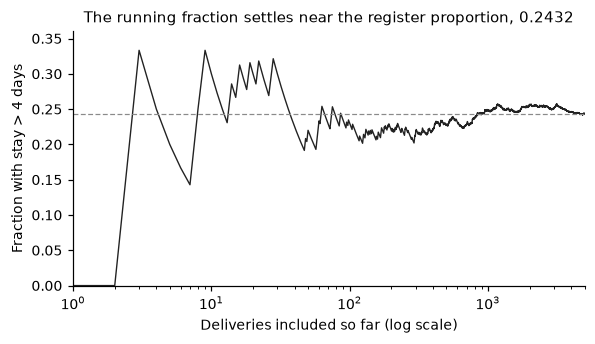

In [4]:
fig, ax = plt.subplots(figsize=(6, 3))
ax.plot(np.arange(1, len(df) + 1), running, color=INK, lw=0.9)
ax.axhline(X.mean(), color=MUTED, lw=0.8, ls=(0, (4, 2)))
ax.set(xscale="log", xlim=(1, 5000), ylim=(0, 0.36),
       xlabel="Deliveries included so far (log scale)", ylabel="Fraction with stay > 4 days",
       title="The running fraction settles near the register proportion, 0.2432")
plt.show()

**Answer to question 1.** 1,216 of the 5,000 deliveries had a stay longer than 4 days: a proportion of **0.2432**. The early fraction wanders more than the later one, which is what the *law of large numbers* describes for repeated independent draws; the curve illustrates it and does not prove it.

#### Events and rules

Three adverse events are recorded: hemorrhage $H$, readmission $R$, and return to theatre $T$. A **clean** delivery here means only that none of the three was recorded; it does not exclude other conditions.

In [5]:
print(int(H.sum()), int(R.sum()), int(T.sum()))
print(int((H & R).sum()), int((H & T).sum()), int(any_event.sum()))

p_h, p_r, p_t = H.mean(), R.mean(), T.mean()
p_hr, p_ht, p_rt, p_hrt = (H & R).mean(), (H & T).mean(), (R & T).mean(), (H & R & T).mean()
print(round(p_h + p_r + p_t, 4))                                    # adds overlaps more than once
print(round(p_h + p_r + p_t - p_hr - p_ht - p_rt + p_hrt, 4))       # inclusion-exclusion
print(round(any_event.mean(), 4), round((~any_event).mean(), 4))    # direct count; complement

299 398 83
133 54 592
0.156
0.1184
0.1184 0.8816


Adding the three probabilities (0.1560) counts deliveries with several events more than once. Subtracting the pairwise overlaps and adding back the triple overlap gives 0.1184, the direct count. The **complement rule** gives the clean share at once: $1-0.1184=0.8816$.

### A.3 Question 2: who has long stays, and who is represented among them?

**Conditional probability** keeps only the group of interest as the denominator. $P(X\mid D)$ is the probability of a long stay *among* women with gestational diabetes.

In [6]:
groups = [("D", D), ("not D", ~D), ("C", C), ("not C", ~C),
          ("any H/R/T", any_event), ("no H/R/T", ~any_event)]
for name, group in groups:
    print(name, int(group.sum()), int((X & group).sum()), f"{X[group].mean():.4f}")
print("D and X", f"{(D & X).mean():.4f}")

D 809 396 0.4895
not D 4191 820 0.1957
C 1499 851 0.5677
not C 3501 365 0.1043
any H/R/T 592 335 0.5659
no H/R/T 4408 881 0.1999
D and X 0.0792


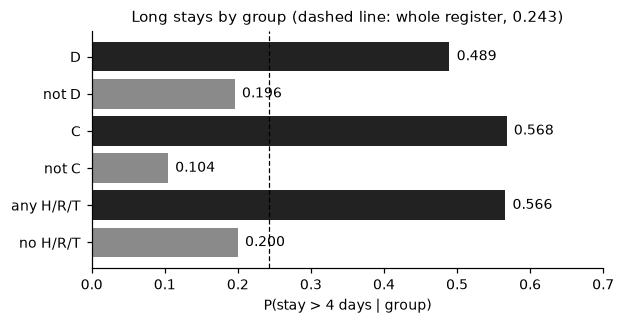

In [7]:
labels = [g[0] for g in groups]
vals = [X[g[1]].mean() for g in groups]
fig, ax = plt.subplots(figsize=(6, 2.8))
bars = ax.barh(labels[::-1], vals[::-1], color=[MUTED, INK] * 3)
ax.axvline(X.mean(), color="black", lw=0.8, ls=(0, (4, 2)))
for b, v in zip(bars, vals[::-1]):
    ax.text(v + 0.01, b.get_y() + b.get_height() / 2, f"{v:.3f}", va="center")
ax.set(xlim=(0, 0.7), xlabel="P(stay > 4 days | group)",
       title="Long stays by group (dashed line: whole register, 0.243)")
plt.show()

**Reading the groups.** A long stay occurs in 396 of 809 women with diabetes (0.489) and in 820 of 4,191 without (0.196); in 851 of 1,499 cesareans (0.568) and 365 of 3,501 vaginal births (0.104); and in 335 of 592 deliveries with any recorded adverse event (0.566). These are descriptive contrasts within one register; they do not estimate what would happen if delivery type or diabetes status were changed.

#### Independence and the multiplication rule

If hemorrhage and readmission were **independent**, the chance of both would be the product of their chances. The multiplication rule, $P(A\text{ and }B)=P(A)\,P(B\mid A)$, holds in general and reduces to the product only under independence.

In [8]:
print(f"{H.mean() * R.mean():.8f}", f"{(H & R).mean():.4f}")      # product vs observed
print(f"{R[H].mean():.4f}", f"{R[~H].mean():.4f}")               # P(R|H), P(R|not H)
chain = D.mean() * H[D].mean() * R[D & H].mean()                 # D, then H given D, then R given D and H
print(f"{chain:.4f}", f"{(D & H & R).mean():.4f}")

0.00476008 0.0266
0.4448 0.0564
0.0090 0.0090


The product under independence is 0.0048, but the register shows 0.0266: readmission is far more common after hemorrhage (0.4448) than without it (0.0564), so the events are *not* independent here. The chain $P(D)P(H\mid D)P(R\mid D\text{ and }H)$ equals the direct joint probability, 45 deliveries in 5,000.

#### Bayes' theorem: who is represented among long stays?

Conditional probability runs from the group to the event. The director also asks the reverse: among the long stays, what share involve diabetes or a cesarean? **Bayes' theorem** reverses the condition: $P(D\mid X)=P(X\mid D)\,P(D)/P(X)$, with $P(X)$ assembled from the two groups.

In [9]:
p_x = X[D].mean() * D.mean() + X[~D].mean() * (~D).mean()
print(f"{p_x:.4f}")
for name, group in [("D", D), ("C", C)]:
    posterior = X[group].mean() * group.mean() / p_x
    print(name, f"{posterior:.4f}", f"{group[X].mean():.4f}")        # Bayes vs direct count

0.2432
D 0.3257 0.3257
C 0.6998 0.6998


**Answer to question 2.** Long stays concentrate among cesareans and women with diabetes. Women with diabetes are 16.2% of the register but 32.6% of long stays (396 of 1,216); cesareans are 30.0% of deliveries but 70.0% of long stays (851 of 1,216). Each delivery counts once in these shares; a share of *bed-days* would weight each delivery by its stay, and answers a different question.

### A.4 Question 3: what does the alert add, and how much concerns acidemia?

Two descriptions of the alert answer different questions. **Sensitivity** is the probability of an alert *given* acidemia; **specificity** is the probability of no alert *given* no acidemia; the **positive predictive value** (PPV) is the probability of acidemia *given* an alert, which is the director's denominator.

In [10]:
print(int((A & F).sum()), int((A & ~F).sum()), int((~A & F).sum()), int((~A & ~F).sum()))
sens = F[A].mean()
spec = (~F)[~A].mean()
prior = A.mean()
posterior = sens * prior / (sens * prior + (1 - spec) * (1 - prior))
print(f"{sens:.4f}", f"{spec:.4f}", f"{prior:.4f}")
print(f"{posterior:.4f}", f"{A[F].mean():.4f}")                    # Bayes vs direct count

197 47 465 4291
0.8074 0.9022 0.0488
0.2976 0.2976


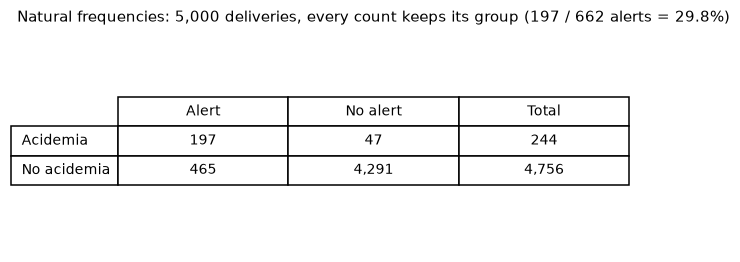

In [11]:
cell = pd.crosstab(A.map({True: "Acidemia", False: "No acidemia"}),
                   F.map({True: "Alert", False: "No alert"}))
cell = cell.loc[["Acidemia", "No acidemia"], ["Alert", "No alert"]]
fig, ax = plt.subplots(figsize=(6, 2.6))
ax.axis("off")
t = ax.table(cellText=[[f"{v:,}" for v in row] + [f"{row.sum():,}"] for _, row in cell.iterrows()],
             rowLabels=cell.index, colLabels=list(cell.columns) + ["Total"], loc="center", cellLoc="center")
t.scale(1, 1.6)
ax.set_title("Natural frequencies: 5,000 deliveries, every count keeps its group (197 / 662 alerts = 29.8%)")
plt.show()

The sensitivity is 0.807 and the specificity 0.902, yet of the 662 alerts only 197 (29.8%) concern births with acidemia and 465 do not. The small false-alert rate acts on a much larger group without acidemia, so false alerts outnumber true ones. Counting in **natural frequencies**, with the reference population in view, makes this visible.

#### Added days and the funded threshold

Each alert adds one maternal bed-day. The next block separates three different quantities: the added days, the added days that fall beyond day 4, and the stays that cross 4 days only because of the added day.

In [12]:
base_stay = df["stay_days"] - F.astype(int)                       # stay without the added day
added_days = df["stay_days"] - base_stay
excess_added = ((df["stay_days"] - 4).clip(lower=0) - (base_stay - 4).clip(lower=0))
crossed = F & (base_stay <= 4) & X
print(int(added_days.sum()), int(added_days[~A].sum()))           # added days; those without acidemia
print(int(excess_added.sum()), int(crossed.sum()))                # beyond day 4; stays that cross
print(int((F & X).sum()), int(F.sum()), f"{X[F].mean():.3f}")
print(int((~F & X).sum()), int((~F).sum()), f"{X[~F].mean():.3f}")

662 465
282 138
282 662 0.426
934 4338 0.215


**Answer to question 3.** The 662 alerts add 662 maternal bed-days; 465 of them follow births without acidemia. Of those added days, 282 fall beyond day 4, and 138 stays cross the 4-day line because of the added day. A long stay occurs in 282 of 662 alerted deliveries (0.426) and in 934 of 4,338 others (0.215).

**What this can and cannot support.** The register holds a binary acidemia flag, not measured pH or treatment effects. The 465 alerts without acidemia therefore do not show that the observation was unnecessary, and the chapter does not claim the alert is or is not worth its cost; that needs clinical information and evidence on benefit that this register does not contain. The Cochrane review of continuous cardiotocography compares monitoring strategies, not this hypothetical software.

### A.5 Question 4: counting for fair selection

When every outcome is equally likely, a probability is a ratio of counts. Three counts cover the unit's quality work: a **combination** (an unordered choice), a **permutation** (an ordering of all), and an **arrangement** (an ordered choice of some). The team and trace numbers below are hypothetical design inputs, not derived from the register.

In [13]:
print(comb(12, 6), 2 * comb(9, 3))                                # pilot draws of 6 of 12 teams; keeping 3 named teams together
print(f"{2 * comb(9, 3) / comb(12, 6):.4f}")
print(factorial(12), perm(12, 2))                                 # training orders; ordered first pair
none = comb(388, 20) / comb(400, 20)                              # 20 of 400 traces, 12 of them disagreeing with an expert reading
print(f"{none:.4f}", f"{1 - none:.4f}")

924 168
0.1818
479001600 132
0.5356 0.4644


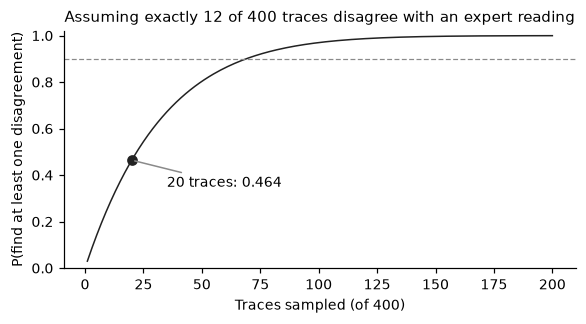

In [14]:
n = np.arange(1, 201)
p_detect = 1 - np.array([comb(388, k) / comb(400, k) for k in n])
fig, ax = plt.subplots(figsize=(6, 2.8))
ax.plot(n, p_detect, color=INK, lw=1)
ax.axhline(0.9, color=MUTED, lw=0.8, ls=(0, (4, 2)))
ax.plot([20], [1 - none], "o", color=INK)
ax.annotate("20 traces: 0.464", (20, 1 - none), (35, 0.35), arrowprops=dict(arrowstyle="-", color=MUTED))
ax.set(xlabel="Traces sampled (of 400)", ylabel="P(find at least one disagreement)", ylim=(0, 1.02),
       title="Assuming exactly 12 of 400 traces disagree with an expert reading")
plt.show()

**Answer to question 4.** Drawing 6 of 12 teams for the pilot has 924 equally likely outcomes; 168 of them keep three named teams together (probability 0.1818). Training all 12 teams in some order has 479,001,600 possible orders. A sample of 20 of 400 traces finds at least one of 12 disagreeing traces with probability 0.4644 (the complement of drawing none, 0.5356).

### A.6 Back to the bed plan

What can the probabilities say about next year's beds?

In [15]:
mean_stay = df["stay_days"].mean()
print(int(df["stay_days"].sum()))
print(f"{mean_stay:.2f}", f"{4 - mean_stay:.2f}")

17666
3.53 0.47


The register records 17,666 initial-stay maternal bed-days. The mean initial stay is 3.53 days, 0.47 days below the hypothetical 4-day allowance. That is *arithmetic*, not proof of spare capacity: stays differ widely (a fraction 0.2432 exceed 4 days), readmission days are excluded, and next year's case mix and volume are unknown. Planning beds needs the distribution of stays (Chapter on distributions) and a way to quantify uncertainty about the future (Chapter on estimation). The probabilities here supply questions and denominators, not a capacity decision.

---

## Part B. Exercise solutions

Each exercise is stated, then solved. Data exercises use the same register; exercises marked *alternative scenario* change an input for that exercise only and say so.

### Exercise 1. The sample space

Describe a delivery by the three indicators $H$, $R$, and $T$. List the eight possible yes-or-no descriptions. Which describe "readmitted but no return to the operating room"? Which describe the complement of "some recorded adverse event"?

**Solution.** Write the indicators in the order (hemorrhage, readmission, return to the operating room) with Y for yes and N for no: NNN, NNY, NYN, NYY, YNN, YNY, YYN, YYY. "Readmitted but no return" is NYN and YYN. The complement of "some recorded adverse event" is NNN only. These are descriptions of records, **not** eight equally likely outcomes.

### Exercise 2. The eight probabilities

Using `data/deliveries.csv`, compute the count and probability of each description in Exercise 1. Check that they add to one, and identify the two most common descriptions involving an adverse event.

In [16]:
counts = df.groupby(["hemorrhage", "readmission", "return_to_theatre"]).size()
for outcome, count in counts.items():
    code_ = "".join("Y" if item == "yes" else "N" for item in outcome)
    print(code_, int(count), f"{count / len(df):.4f}")
print("Total", int(counts.sum()), f"{counts.sum() / len(df):.4f}")

NNN 4408 0.8816
NNY 28 0.0056
NYN 264 0.0528
NYY 1 0.0002
YNN 144 0.0288
YNY 22 0.0044
YYN 101 0.0202
YYY 32 0.0064
Total 5000 1.0000


**Solution.** The descriptions divide the register without overlap, so the probabilities add to exactly one. Among descriptions with an adverse event, readmission alone is the most common (264 deliveries, 0.0528), followed by hemorrhage alone (144, 0.0288). NNN means no recorded $H$, $R$, or $T$; it does not exclude other conditions.

### Exercise 3. Hemorrhage or return to the operating room

The register has 299 hemorrhages, 83 returns to the operating room, and 54 deliveries with both. Calculate $P(H\text{ or }T)$ by the addition rule and by direct count. Explain why the events are neither mutually exclusive nor independent.

In [17]:
print(int((H | T).sum()), f"{(H | T).mean():.4f}")
print(f"{H.mean() * T.mean():.8f}", f"{(H & T).mean():.4f}")

328 0.0656
0.00099268 0.0108


**Solution.** Subtract the overlap once: $P(H\text{ or }T)=(299+83-54)/5{,}000=328/5{,}000=0.0656$. They are not mutually exclusive because 54 deliveries have both. Under independence the joint probability would be $0.0598\times0.0166=0.00099$, but the observed value is $54/5{,}000=0.0108$, about eleven times larger, so the events are dependent in this register.

### Exercise 4. Delivery type and long stays

Calculate $P(X\mid C)$, $P(X\mid\text{not }C)$, and their risk ratio with exact counts. Then calculate $P(C\mid X)$ by Bayes' theorem and by direct count. Explain why a share of long-stay deliveries is not a share of bed-days.

In [18]:
p_x_c = X[C].mean()
p_x_not_c = X[~C].mean()
p_x = p_x_c * C.mean() + p_x_not_c * (~C).mean()
print(f"{p_x_c:.4f}", f"{p_x_not_c:.4f}", f"{p_x_c / p_x_not_c:.2f}")
print(f"{p_x_c * C.mean() / p_x:.4f}", f"{C[X].mean():.4f}")

0.5677 0.1043 5.45
0.6998 0.6998


**Solution.** $P(X\mid C)=851/1{,}499\approx0.568$ and $P(X\mid\text{not }C)=365/3{,}501\approx0.104$, a ratio of about 5.45. Bayes gives $P(C\mid X)=851/1{,}216\approx0.700$, equal to the direct count. Each delivery counts once in that share; a share of bed-days would weight each delivery by its length of stay. The risk ratio is descriptive and does not estimate the effect of changing delivery type.

### Exercise 5. Three events in sequence

Calculate the probability of cesarean delivery, hemorrhage, and return to the operating room together with the multiplication rule $P(C)\,P(H\mid C)\,P(T\mid C\text{ and }H)$. Check it against the direct count and state the denominator of each factor.

In [19]:
chain = C.mean() * H[C].mean() * T[C & H].mean()
print(int(C.sum()), int((C & H).sum()), int((C & H & T).sum()))
print(f"{chain:.4f}", f"{(C & H & T).mean():.4f}")

1499 114 29
0.0058 0.0058


**Solution.** There are 1,499 cesareans, 114 with hemorrhage, and 29 with hemorrhage and return: $\frac{1{,}499}{5{,}000}\cdot\frac{114}{1{,}499}\cdot\frac{29}{114}=\frac{29}{5{,}000}=0.0058$. The first denominator is all deliveries, the second all cesareans, the third cesareans with hemorrhage. Both routes identify the same 29 deliveries.

### Exercise 6. Alternative alert performance (alternative scenario)

A proposed alert has 95% sensitivity and a 10% false-positive rate. Calculate its PPV at the register's exact acidemia prevalence (244/5,000 = 0.0488) and at a hypothetical prevalence of 20%. Compare both with an alert with 80% sensitivity and a 10% false-positive rate at prevalence 0.0488. These are assumed performance values, not observed results. Explain the role of prevalence.

In [20]:
scenarios = [(0.95, A.mean()), (0.95, 0.20), (0.80, A.mean())]
for sensitivity, prevalence in scenarios:
    ppv = sensitivity * prevalence / (sensitivity * prevalence + 0.10 * (1 - prevalence))
    print(f"{sensitivity:.2f}", f"{prevalence:.4f}", f"{ppv:.4f}")

0.95 0.0488 0.3277
0.95 0.2000 0.7037
0.80 0.0488 0.2910


**Solution.** The PPVs are about 32.8%, 70.4%, and 29.1%. Higher sensitivity at fixed prevalence raises the acidemic contribution. Higher prevalence enlarges the acidemic group and shrinks the non-acidemic one, so false alerts weigh less. The scenarios assume the stated sensitivity and false-positive rate hold; they do not show how a replacement alert would perform.

### Exercise 7. Scaled natural frequencies

Scale the observed alert counts to 10,000 deliveries with the same proportions and sketch a natural-frequency tree. Write one sentence with percentages and one with counts for the director, naming the reference population and the added maternal bed-days among births without acidemia. Explain why these are not necessarily days beyond the allowance or unnecessary observation.

In [21]:
scale = 10_000 / len(df)
table = pd.DataFrame({"Alert": [(A & F).sum() * scale, (~A & F).sum() * scale],
                      "No alert": [(A & ~F).sum() * scale, (~A & ~F).sum() * scale]},
                     index=["Acidemia present", "Acidemia absent"]).round().astype(int)
table["Total"] = table.sum(axis=1)
table.loc["Total"] = table.sum()
table

,Alert,No alert,Total
Acidemia present,394,94,488
Acidemia absent,930,8582,9512
Total,1324,8676,10000


**Solution.** Doubling each count gives:

| | Alert | No alert | Total |
|---|---:|---:|---:|
| Acidemia present | 394 | 94 | 488 |
| Acidemia absent | 930 | 8,582 | 9,512 |
| Total | 1,324 | 8,676 | 10,000 |

Percentages: among 10,000 deliveries with the register's proportions, 13.24% have alerts, and about 70.2% of those alerts concern births without acidemia, adding 930 maternal bed-days. Counts: 1,324 deliveries have alerts, 394 with acidemia and 930 without; the latter add 930 bed-days. The scaled counts preserve proportions; they are not a forecast. Whether an added day lies beyond day 4 depends on the stay before it, and whether observation is necessary needs clinical information absent from this register.

### Exercise 8. Ordering four selected teams

Four teams are already selected for training, including T11 and T12. All orders of these four, one per quarter, are equally likely. How many orders are possible? What is the probability that T12 goes first; that T12 goes first and T11 second; that T11 and T12 are last, in either order?

In [22]:
from itertools import permutations
orders = list(permutations(["T9", "T10", "T11", "T12"]))
first = sum(o[0] == "T12" for o in orders)
first_second = sum(o[0] == "T12" and o[1] == "T11" for o in orders)
last_two = sum(set(o[2:]) == {"T11", "T12"} for o in orders)
print(len(orders), first / len(orders), first_second / len(orders), last_two / len(orders))

24 0.25 0.08333333333333333 0.16666666666666666


**Solution.** There are $4!=24$ orders. T12 first leaves $3!=6$ orders: $6/24=1/4$. T12 first and T11 second leaves $2!=2$: $2/24=1/12$. T11 and T12 in the last two places can swap, and so can the first two: $2\cdot2/24=1/6$. No selection of four from twelve is needed; the four teams are fixed before their order is drawn.

### Exercise 9. The minimum trace sample

For the unit's hypothetical archive of 400 traces, assume exactly 12 classifications disagree with an expert reading. Find the smallest simple random sample without replacement giving at least a 90% probability of finding one or more. Use `comb` and check the preceding size.

In [23]:
for n in range(1, 401):
    detection = 1 - comb(388, n) / comb(400, n)
    if detection >= 0.90:
        print(n, f"{detection:.5f}")
        previous = 1 - comb(388, n - 1) / comb(400, n - 1)
        print(n - 1, f"{previous:.5f}")
        break

69 0.90047
68 0.89674


**Solution.** $P(\text{at least one})=1-\binom{388}{n}\big/\binom{400}{n}$. The minimum is **69 traces** (0.90047), and 68 gives 0.89674. The probability cannot fall as the sample grows: once a disagreement has appeared, adding a trace cannot remove it. The result depends on the assumed 12 disagreements and on simple random sampling.

### Exercise 10. Alternative marginal probabilities (alternative scenario)

Suppose $P(H)=0.02$ and $P(R)=0.06$, replacing the register's values for this exercise only. The director adds them and reports an 8% probability of hemorrhage or readmission. What assumption makes that sum valid? Is it justified? Give the range of the true probability without assuming independence.

**Solution.** The addition rule is $P(H\text{ or }R)=0.02+0.06-P(H\text{ and }R)$, so the plain sum is valid only if $P(H\text{ and }R)=0$, that is, the events are mutually exclusive. The two marginal probabilities do not justify that, and in this unit hemorrhage often precedes readmission. Without independence the overlap can be anything from 0 to 0.02, so the true probability lies between $\max(0.02,0.06)=0.06$ (every hemorrhage is followed by readmission) and $0.02+0.06=0.08$ (none is).

### Exercise 11. Five years of 200 deliveries (alternative scenario)

This unit anticipates only 200 deliveries per year for five years. Simulate independent long-stay indicators with constant probability equal to the register's exact proportion, 0.2432, using `random.Random(10)`. Report the five annual proportions and the cumulative proportion after each year. Explain why a fixed generating probability does not give identical annual fractions, and what information is still needed to plan beds.

In [24]:
rng = random.Random(10)
probability = float(X.mean())
annual_counts = [sum(rng.random() < probability for _ in range(200)) for _ in range(5)]
cumulative = 0
for year, count in enumerate(annual_counts, start=1):
    cumulative += count
    print(year, count, f"{count / 200:.4f}", f"{cumulative / (200 * year):.4f}")

1 43 0.2150 0.2150
2 55 0.2750 0.2450
3 47 0.2350 0.2417
4 41 0.2050 0.2325
5 45 0.2250 0.2310


**Solution.** The annual proportions are 0.2150, 0.2750, 0.2350, 0.2050, and 0.2250, with cumulative proportions 0.2150, 0.2450, 0.2417, 0.2325, and 0.2310. A fixed probability governs each delivery, not each year's count, so annual counts vary around the expectation of about 48.6. Planning beds also needs each stay's length, the allowance, the days used by stays within 4, and a case mix comparable to the register's.

### Exercise 12. Kinds of probability

Classify each statement as conditional, joint, or marginal, and write it in symbols: (a) 72 of the 809 deliveries involving diabetes have hemorrhage; (b) 72 of all 5,000 deliveries involve both diabetes and hemorrhage; (c) 299 of all 5,000 have hemorrhage; (d) 72 of the 299 deliveries with hemorrhage involve diabetes; (e) 197 of 662 alerted births have acidemia.

In [25]:
print(int((H & D).sum()), int(D.sum()), int(H.sum()), int((A & F).sum()), int(F.sum()))

72 809 299 197 662


**Solution.** (a) conditional, $P(H\mid D)=72/809$. (b) joint, $P(H\text{ and }D)=72/5{,}000$. (c) marginal, $P(H)=299/5{,}000$. (d) conditional, $P(D\mid H)=72/299$. (e) conditional, $P(\text{acidemia}\mid\text{alert})=197/662$. The denominator tells which kind it is.

---
*Synthetic data (seed 11, `chapters/ch11/generate_data.py`). Nothing in this notebook is a clinical recommendation or an estimate for a real unit.*